# Eksperimen Pribadi — Tugas 3: Integrasi Multimodal — **Early Fusion**

**Early fusion** = menggabungkan fitur dari semua sumber (kurs, lexicon, embedding, topik, entitas) **di level fitur** (digabung/*concatenate*) sebelum masuk ke **satu** model prediktor. Kebalikannya **late fusion**: tiap sumber punya model sendiri, lalu *prediksi*-nya digabung (notebook berikutnya).

**Kerangka Model A / B / C**
- **A** = kurs saja (7 fitur).
- **B** = A + 16 fitur lexicon.
- **C** = A + fitur teks berbasis embedding/topik/entitas (di sini difusikan secara bertahap).

**Blok fitur** (semua sudah diuji terpisah di Bagian A–B.v; fitur dipilih **di muka**, bukan dari val/test):

| Blok | Isi | Dimensi |
|---|---|---|
| kurs | lag 1–5, rata-rata dan std 5 hari | 7 |
| lex | VADER + Loughran-McDonald | 16 |
| emb | FinBERT, rata-rata harian → PCA 10 (fit train) | 10 |
| sent | sentimen FinBERT harian (pos/neg/neu, net rata-rata/min/maks) | 6 |
| topic | porsi harian tema BERTopic (fit train, MiniLM embedding) | ±K |
| ner | porsi harian negara, bank sentral, peristiwa ekonomi (22) | 22 |

**Yang diuji**
1. **Ablation bertahap:** A → B → C1 (+emb) → C2 (+sent) → C3 (+topic) → C4 (+ner) → C5 (semua).
2. **Add-one:** A + tiap blok sendiri; **leave-one-out:** fusi penuh dikurangi satu blok. Menjawab: blok mana yang berkontribusi?
3. **Strategi penggabungan:** *concat mentah*, *seimbang antar blok* (bobot 1/√dimensi), dan *reduksi gabungan* (PCA atas blok teks).
4. **Uji berpasangan (block bootstrap)** terhadap A dan Konstan, supaya klaim "lebih baik" punya selang kepercayaan, bukan sekadar selisih angka.

**Tidak ada kebocoran:** scaler, PCA, BERTopic, dan semua fit hanya di train; val/test hanya di-transform. Tuning hiperparameter dikerjakan terpisah.

**Prasyarat cache** (di `cache_embeddings/`): `FinBERT_cw300_mc2_ml512.npz`, `MiniLM_cw160_mc5_ml256.npz`, `ner_spacy_en_core_web_sm.pkl`. Perlu `pip install bertopic umap-learn hdbscan`. Blok yang bahannya tidak ada dilewati.

## 0. Setup

In [1]:
import sys, re, json, time, pickle, warnings
from collections import Counter
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
warnings.filterwarnings("ignore")

def find_root():
    """Cari root repo dari folder notebook (jalan dari notebook/ maupun src/notebook/)."""
    here = Path.cwd().resolve()
    for q in (here, *here.parents):
        if (q / "data" / "export" / "articles.parquet").exists() and (q / "src" / "eval_utils.py").exists():
            return q
    raise FileNotFoundError("root repo (data/export + src/eval_utils.py) tidak ditemukan dari " + str(here))

ROOT = find_root()
sys.path.append(str(ROOT / "src"))
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = ROOT / "data" / "export"
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("root repo:", ROOT)

root repo: /Users/farsyaant/nlpproject-baru


## 1. Muat data dan split

In [2]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


In [3]:
is_tr = (articles["split"] == "train").to_numpy(); has_split = articles["split"].notna().to_numpy()
has_news = (daily["news_count"] > 0).to_numpy()
texts = articles["text_raw"].tolist()

def daily_mean(M):
    '''Rata-rata per aligned_trading_date; hari tanpa berita = rata-rata hari train (netral).'''
    df = pd.DataFrame(M[has_split]); df["date"] = articles.loc[has_split, "aligned_trading_date"].to_numpy()
    d = df.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); out = d.to_numpy(float).copy()
    out[~has] = out[tr & has].mean(axis=0)
    return out

BLK = {}      # nama blok -> (matriks harian, nama kolom)
BLK["kurs"] = (daily[KURS_COLS].to_numpy(), KURS_COLS)
BLK["lex"] = (daily[LEX_COLS].to_numpy(), LEX_COLS)
print({k: v[0].shape for k, v in BLK.items()})

{'kurs': (1194, 7), 'lex': (1194, 16)}


## 2. Blok emb dan sent (FinBERT)
Embedding artikel dirata-rata per hari lalu PCA 10 komponen (**fit hanya hari train**); hari tanpa berita = 0 di ruang PCA. Sentimen = 6 fitur harian dari probabilitas FinBERT.

In [4]:
KS = (5, 10, 20)

def pca_daily(A, kmax=max(KS)):
    keep = articles["split"].notna().to_numpy()
    emb = pd.DataFrame(A[keep]); emb["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    d = emb.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); D = d.to_numpy(dtype=float)
    pca = PCA(n_components=kmax, random_state=SEED).fit(D[tr & has])        # TRAIN saja
    Z = np.zeros((len(daily), kmax)); Z[has] = pca.transform(D[has])
    return {k: Z[:, :k] for k in KS}, int(has.sum()), float(pca.explained_variance_ratio_.sum())

def finbert_daily(P, labels):
    idx = {v: k for k, v in labels.items()}
    pos, neg, neu = P[:, idx["positive"]], P[:, idx["negative"]], P[:, idx["neutral"]]
    keep = articles["split"].notna().to_numpy()
    df = pd.DataFrame({"fb_pos": pos, "fb_neg": neg, "fb_neu": neu, "net": pos - neg})[keep]
    df["date"] = articles.loc[keep, "aligned_trading_date"].to_numpy()
    g = df.groupby("date")
    out = pd.DataFrame({"fb_pos_mean": g["fb_pos"].mean(), "fb_neg_mean": g["fb_neg"].mean(),
                        "fb_neu_mean": g["fb_neu"].mean(), "fb_net_mean": g["net"].mean(),
                        "fb_net_min": g["net"].min(), "fb_net_max": g["net"].max()})
    return out.reindex(daily["date"]).fillna(0.0).to_numpy()

fb_f = CACHE_DIR / "FinBERT_cw300_mc2_ml512.npz"
if fb_f.exists():
    z = np.load(fb_f, allow_pickle=True); assert len(z["A"]) == len(articles)
    Zs, n_days, evr = pca_daily(z["A"].astype(float))
    BLK["emb"] = (Zs[10], [f"fbpc{i + 1}" for i in range(10)])
    sent6 = finbert_daily(z["P"], z["labels"].item())
    BLK["sent"] = (sent6, ["fb_pos", "fb_neg", "fb_neu", "fb_net_mean", "fb_net_min", "fb_net_max"])
    print(f"FinBERT: PCA10 EVR(20 komponen)={evr:.3f} | hari berfitur: {n_days}")
else:
    print("cache FinBERT belum ada -> blok emb dan sent dilewati")

FinBERT: PCA10 EVR(20 komponen)=0.795 | hari berfitur: 1073


## 3. Blok topic (BERTopic)
BERTopic memakai embedding MiniLM dari cache (UMAP → HDBSCAN → c-TF-IDF), di-fit **hanya pada artikel train**; val/test di-transform. Fitur = porsi artikel per tema per hari (tanpa kolom outlier).

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
DOMAIN_STOP = {"said", "say", "says", "year", "years", "new", "also", "would", "could", "one", "two", "like",
               "just", "percent", "according", "told", "may", "last", "first", "still", "even", "much", "many",
               "since", "week", "month", "time", "company", "companies", "cnbc", "reuters", "getty", "images",
               "video", "watch", "https", "com", "inc", "corp"}
STOP = set(ENGLISH_STOP_WORDS) | DOMAIN_STOP

In [6]:
BT_OK = False
try:
    from bertopic import BERTopic
    from umap import UMAP
    from hdbscan import HDBSCAN
    mini_f = CACHE_DIR / "MiniLM_cw160_mc5_ml256.npz"
    if not mini_f.exists():
        print("cache MiniLM belum ada -> BERTopic dilewati")
    else:
        E = np.load(mini_f, allow_pickle=True)["A"]
        docs = articles["text_raw"].tolist()
        MIN_CLUSTER = 40          # ukuran klaster minimum; kecilkan untuk tema lebih banyak
        bt = BERTopic(
            embedding_model=None,
            umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
            hdbscan_model=HDBSCAN(min_cluster_size=MIN_CLUSTER, metric="euclidean",
                                  cluster_selection_method="eom", prediction_data=True),
            vectorizer_model=CountVectorizer(stop_words=list(STOP), min_df=5, ngram_range=(1, 2)),
            calculate_probabilities=False, verbose=False)
        tr_idx = np.where(is_tr)[0]
        bt.fit([docs[i] for i in tr_idx], embeddings=E[tr_idx])                    # FIT hanya train
        all_topics, _ = bt.transform(docs, embeddings=E)                           # val/test: transform saja
        BT = np.array(all_topics)
        T_IDS = sorted(set(BT[is_tr]) - {-1})
        BT_OK = len(T_IDS) >= 2
        print(f"BERTopic: {len(T_IDS)} tema | artikel train tanpa topik (outlier): {(BT[is_tr] == -1).mean():.1%}")
        for t in T_IDS:
            words = ", ".join(w for w, _ in bt.get_topic(t)[:8])
            print(f"B{t:02d} [{(BT[is_tr] == t).mean():5.1%} dari train] {words}")
except (ImportError, ValueError) as e:
    print("bertopic/umap/hdbscan belum terpasang ->", e)

BERTopic: 13 tema | artikel train tanpa topik (outlier): 22.0%
B00 [15.0% dari train] ukraine, russia, russian, military, war, ukrainian, putin, russias
B01 [14.5% dari train] oil, energy, prices, crude, gas, climate, opec, oil prices
B02 [13.5% dari train] inflation, market, fed, investors, stocks, markets, stock, rate
B03 [ 7.8% dari train] israel, israeli, gaza, hamas, iran, hezbollah, war, palestinian
B04 [ 7.4% dari train] china, taiwan, chinese, beijing, chinas, xi, countries, russia
B05 [ 5.2% dari train] china, chinese, chinas, growth, hong, market, investment, economic
B06 [ 2.8% dari train] russia, space, russian, cyber, ukraine, internet, information, services
B07 [ 2.7% dari train] global, world, economic, growth, debt, economy, risk, report
B08 [ 2.2% dari train] dollar, yen, currency, data, euro, rate, bank, fed
B09 [ 1.7% dari train] inflation, rate, central, bank, ecb, rates, policy, central bank
B10 [ 1.8% dari train] chips, chip, semiconductor, manufacturing, china, a

In [7]:
if BT_OK:
    ONEHOT = np.stack([(BT == t) for t in T_IDS], axis=1).astype(float)
    BLK["topic"] = (daily_mean(ONEHOT), [f"B{t:02d}" for t in T_IDS])
    print("blok topic:", BLK["topic"][0].shape)

blok topic: (1194, 13)


## 4. Blok ner (entitas)
Memakai hasil spaCy NER yang sama dengan B.iii (di-cache) + kamus alias negara/bank sentral + pola peristiwa ekonomi. Fitur = porsi harian artikel yang menyebut 8 negara terbesar (train), 3 kelompok bank sentral, dan 11 jenis peristiwa ekonomi.

In [8]:
%pip install bertopic umap-learn hdbscan

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
NER_MODEL = "en_core_web_sm"
ner_f = CACHE_DIR / f"ner_spacy_{NER_MODEL}.pkl"
texts = articles["text_raw"].tolist()
is_tr = (articles["split"] == "train").to_numpy()
has_split = articles["split"].notna().to_numpy()
ents = None
if ner_f.exists():
    saved = pickle.load(open(ner_f, "rb"))
    if saved["n"] == len(texts):
        ents = saved["ents"]; print(f"NER dimuat dari cache {ner_f.name}")
if ents is None:
    import spacy
    nlp = spacy.load(NER_MODEL, disable=["parser", "lemmatizer", "tagger", "attribute_ruler"])
    t0 = time.time(); ents = []
    for i, d in enumerate(nlp.pipe(texts, batch_size=32)):
        ents.append([(e.text, e.label_) for e in d.ents])
        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{len(texts)} artikel | {time.time() - t0:.0f}s", flush=True)
    pickle.dump({"n": len(texts), "model": NER_MODEL, "ents": ents}, open(ner_f, "wb"))
    print(f"NER selesai dalam {time.time() - t0:.0f}s")
print("label entitas terbanyak:", Counter(l for es in ents for _, l in es).most_common(8))

NER dimuat dari cache ner_spacy_en_core_web_sm.pkl
label entitas terbanyak: [('GPE', 105179), ('ORG', 78418), ('DATE', 66681), ('PERSON', 50533), ('NORP', 27702), ('CARDINAL', 20893), ('PERCENT', 17483), ('LOC', 13337)]


In [10]:
def norm(s):
    s = s.lower().replace("’", "'").replace(".", "").strip()
    return re.sub(r"^the\s+", "", s)

COUNTRY_GROUPS = {   # kelompok -> alias (sudah dinormalisasi)
    "US": ["us", "united states", "america", "american", "americans", "usa", "washington", "white house", "pentagon"],
    "China": ["china", "chinese", "beijing"],
    "Russia": ["russia", "russian", "russians", "moscow", "kremlin"],
    "Ukraina": ["ukraine", "ukrainian", "ukrainians", "kyiv", "kiev", "crimea"],
    "Israel_Palestina": ["israel", "israeli", "israelis", "gaza", "palestinian", "palestinians", "palestine", "west bank", "hamas"],
    "Iran": ["iran", "iranian", "iranians", "tehran"],
    "Jepang": ["japan", "japanese", "tokyo"],
    "Eropa": ["eu", "european union", "europe", "european", "germany", "german", "france", "french", "brussels", "berlin", "paris"],
    "Inggris": ["uk", "united kingdom", "britain", "british", "london"],
    "India": ["india", "indian", "delhi", "new delhi"],
    "Teluk": ["saudi arabia", "saudi", "qatar", "uae", "united arab emirates", "kuwait", "gulf", "riyadh"],
    "Taiwan": ["taiwan", "taiwanese", "taipei"],
    "Korea": ["north korea", "south korea", "korea", "korean", "pyongyang", "seoul"],
    "Indonesia": ["indonesia", "indonesian", "jakarta", "rupiah"],
}
CB_GROUPS = {        # bank sentral -> alias NER (ORG / PERSON)
    "Fed": ["fed", "federal reserve", "fomc", "federal open market committee", "powell", "jerome powell"],
    "ECB": ["ecb", "european central bank", "lagarde", "christine lagarde"],
    "BOJ": ["boj", "bank of japan", "ueda", "kazuo ueda"],
    "BOE": ["boe", "bank of england", "andrew bailey"],
    "PBOC": ["pboc", "people's bank of china", "pbc"],
    "Lainnya": ["rba", "reserve bank of australia", "snb", "swiss national bank", "rbi", "reserve bank of india",
                "bank of canada", "bank indonesia", "bank of korea"],
}
CB_REGEX = {         # pencarian kamus langsung pada teks (singkatan peka huruf besar)
    "Fed": r"\b(Fed|Federal Reserve|FOMC|Powell)\b",
    "ECB": r"\b(ECB|European Central Bank|Lagarde)\b",
    "BOJ": r"\b(BOJ|Bank of Japan|Ueda)\b",
    "BOE": r"\b(BOE|Bank of England)\b",
    "PBOC": r"\b(PBOC|PBoC|People.s Bank of China)\b",
    "Lainnya": r"\b(RBA|Reserve Bank of Australia|SNB|Swiss National Bank|RBI|Reserve Bank of India|Bank of Canada|Bank Indonesia|Bank of Korea)\b",
}
ECON_EVENTS = {      # peristiwa ekonomi -> pola (tidak peka huruf besar)
    "keputusan_suku_bunga": r"\b(rate (hike|cut|increase|decrease)s?|(raise|raised|raising|cut|cuts|cutting|lower|lowered|hike|hiked|hold|held) (interest )?rates?)\b",
    "inflasi": r"\b(inflation|CPI|consumer price)\b",
    "pertumbuhan_PDB": r"\b(GDP|gross domestic product|economic growth)\b",
    "tarif_dagang": r"\b(tariffs?|trade war|trade deal)\b",
    "sanksi": r"\bsanctions?\b",
    "resesi": r"\b(recession|stagflation|downturn)\b",
    "tenaga_kerja": r"\b(jobs report|nonfarm|payrolls?|unemployment)\b",
    "utang_default": r"\b(default|debt ceiling|sovereign debt|credit rating|downgrade)\b",
    "minyak_energi": r"\b(oil prices?|crude|Brent|WTI|OPEC)\b",
    "krisis_bank": r"\b(bank failure|banking crisis|bank run|Credit Suisse|Silicon Valley Bank|SVB)\b",
    "mata_uang": r"\b(dollar|yen|yuan|currency|exchange rate|rupiah)\b",
}
ALIAS_C = {a: g for g, al in COUNTRY_GROUPS.items() for a in al}
ALIAS_CB = {a: g for g, al in CB_GROUPS.items() for a in al}
C_LABELS, CB_LABELS = {"GPE", "NORP", "LOC", "ORG"}, {"ORG", "PERSON"}

n = len(articles)
cg, cbg, evg = list(COUNTRY_GROUPS), list(CB_GROUPS), list(ECON_EVENTS)
C_FLAG = np.zeros((n, len(cg)), bool); CB_NER = np.zeros((n, len(cbg)), bool)
CB_RX = np.zeros((n, len(cbg)), bool); EV_FLAG = np.zeros((n, len(evg)), bool)
cb_rx_c = {g: re.compile(p) for g, p in CB_REGEX.items()}
ev_rx_c = {g: re.compile(p, re.I) for g, p in ECON_EVENTS.items()}
for i, (es, t) in enumerate(zip(ents, texts)):
    for s, lab in es:
        k = norm(s)
        if lab in C_LABELS and k in ALIAS_C: C_FLAG[i, cg.index(ALIAS_C[k])] = True
        if lab in CB_LABELS and k in ALIAS_CB: CB_NER[i, cbg.index(ALIAS_CB[k])] = True
    for j, g in enumerate(cbg): CB_RX[i, j] = bool(cb_rx_c[g].search(t))
    for j, g in enumerate(evg): EV_FLAG[i, j] = bool(ev_rx_c[g].search(t))
CB_FLAG = CB_NER | CB_RX                                   # gabungan NER + kamus teks
CB_ANY = CB_FLAG.any(1); CB_FED = CB_FLAG[:, cbg.index("Fed")]
CB_OTHER = CB_FLAG[:, [j for j, g in enumerate(cbg) if g != "Fed"]].any(1)
ECON_ANY = EV_FLAG.any(1); US_FLAG = C_FLAG[:, cg.index("US")]
print("kamus siap")

kamus siap


In [11]:
top8 = list(np.argsort(-C_FLAG[is_tr].mean(0))[:8])
E1 = daily_mean(C_FLAG[:, top8].astype(float)); n1 = [f"neg_{cg[j]}" for j in top8]
E2 = daily_mean(np.stack([CB_ANY, CB_FED, CB_OTHER], 1).astype(float)); n2 = ["cb_semua", "cb_Fed", "cb_lain"]
E3 = daily_mean(EV_FLAG.astype(float)); n3 = [f"ev_{g}" for g in evg]
BLK["ner"] = (np.hstack([E1, E2, E3]), n1 + n2 + n3)
print({k: v[0].shape[1] for k, v in BLK.items()})

{'kurs': 7, 'lex': 16, 'emb': 10, 'sent': 6, 'topic': 13, 'ner': 22}


## 5. Protokol evaluasi (identik dengan notebook sebelumnya)
Ditambah penyimpanan prediksi rata-rata 3 model (`PRED`) untuk uji berpasangan.

In [12]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    Xs = StandardScaler().fit(X[tr]).transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

ret_today = daily["ret"].to_numpy(); base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

In [13]:
PRED = {}
def run2(set_name, X, w=None):
    '''Sama dengan run() sebelumnya; w = bobot kolom setelah standardisasi (untuk strategi seimbang antar blok).'''
    Xs = StandardScaler().fit(X[tr]).transform(X)
    if w is not None: Xs = Xs * w
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    for mname, p in preds.items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))
    PRED[set_name] = np.mean(list(preds.values()), axis=0)

def fuse(names, mode="concat"):
    '''Gabungkan blok (urutan = names). mode: concat | balanced (bobot 1/sqrt(dim blok)).'''
    X = np.hstack([BLK[n][0] for n in names])
    w = None
    if mode == "balanced":
        w = np.concatenate([np.full(BLK[n][0].shape[1], 1.0 / np.sqrt(BLK[n][0].shape[1])) for n in names])
    return X, w

def fuse_pca(text_names, k=10):
    '''Reduksi gabungan: standardisasi blok teks, PCA k (fit hari train), lalu digabung dengan kurs.'''
    Xt = np.hstack([BLK[n][0] for n in text_names])
    sc = StandardScaler().fit(Xt[tr]); Xz = sc.transform(Xt)
    Zp = PCA(n_components=k, random_state=SEED).fit(Xz[tr]).transform(Xz)
    return np.hstack([BLK["kurs"][0], Zp])

## 6. Menjalankan eksperimen
Blok yang tidak tersedia dilewati otomatis. Nama set diawali **F** (fusi).

In [14]:
AV = [b for b in ("lex", "emb", "sent", "topic", "ner") if b in BLK]
print("blok tersedia:", AV)

run2("A  kurs", fuse(["kurs"])[0])
run2("B  kurs+lex", fuse(["kurs", "lex"])[0])

# (1) ablation bertahap: tambah blok satu per satu (urutan tetap, ditetapkan di muka)
steps = [b for b in ("emb", "sent", "topic", "ner") if b in BLK]
cur = ["kurs"]
for i, b in enumerate(steps, 1):
    cur = cur + [b]; run2(f"F  C{i} kurs+{'+'.join(cur[1:])}", fuse(cur)[0])
full = ["kurs"] + AV
run2(f"F  C{len(steps) + 1} FULL (semua blok)", fuse(full)[0])

# (2) add-one dan leave-one-out
for b in AV:
    run2(f"F  add-one: kurs+{b}", fuse(["kurs", b])[0])
for b in AV:
    run2(f"F  leave-out: FULL - {b}", fuse([x for x in full if x != b])[0])

# (3) strategi penggabungan untuk FULL
X, w = fuse(full, "balanced"); run2("F  FULL seimbang-blok", X, w)
run2("F  FULL + PCA gabungan (k=10)", fuse_pca(AV, 10))
res = pd.DataFrame(rows); base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set x", res["model"].nunique(), "model")

blok tersedia: ['lex', 'emb', 'sent', 'topic', 'ner']
selesai: 19 set x 3 model


## 7. Hasil

### 7.1 Pembanding tanpa model

In [15]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 7.2 Rata-rata 3 model per set
`dRMSE%` terhadap A (negatif = lebih baik).

In [16]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                             test      val     test      val     test      val     test      val      val     test
set                                                                                                                    
F  C3 kurs+emb+sent+topic      0.00293  0.00338  0.50947  0.50379  0.53223  0.51548  0.06756  0.03709 -1.45763 -3.27176
F  add-one: kurs+topic         0.00297  0.00339  0.43939  0.50189  0.50499  0.51604  0.01324  0.03385 -1.14486 -1.91688
F  leave-out: FULL - ner       0.00295  0.00340  0.49432  0.51894  0.51015  0.52993  0.01844  0.06494 -1.13079 -2.46044
F  C2 kurs+emb+sent            0.00294  0.00341  0.49053  0.50189  0.53259  0.52123  0.06465  0.05271 -0.82497 -2.90279
F  add-one: kurs+emb           0.00295  0.00341  0.48295  0.50758  0.52475  0.52681  0.04366  0.06447 -0.77822 -2.60402
F  C1 kurs+emb                 0.00295  0.00341  0.48295  0.50758  0.52475  0.52681  0.04366  0.06447 -0.77822 -2.60402
F  C4 kurs+emb+sent+topic+ner  0.00291  0.00342  0.53030  0.49432  0.54060  0.50532  0.08678  0.01469 -0.48656 -3.72516
F  leave-out: FULL - lex       0.00291  0.00342  0.53030  0.49432  0.54060  0.50532  0.08678  0.01469 -0.48656 -3.72516
F  FULL seimbang-blok          0.00294  0.00342  0.53220  0.48295  0.53935  0.49442  0.08061 -0.01011 -0.47803 -2.95898
F  FULL + PCA gabungan (k=10)  0.00296  0.00342  0.50758  0.50189  0.54915  0.51449  0.10701  0.03277 -0.41298 -2.39687
F  add-one: kurs+ner           0.00296  0.00343  0.47727  0.46970  0.52778  0.48512  0.06713 -0.03848 -0.15851 -2.07399
F  add-one: kurs+sent          0.00303  0.00343  0.45076  0.48106  0.52101  0.50251  0.05447 -0.00515 -0.05899  0.10689
A  kurs                        0.00303  0.00343  0.40720  0.47159  0.49769  0.49728 -0.03028 -0.01454  0.00000  0.00000
F  C5 FULL (semua blok)        0.00294  0.00344  0.53977  0.48864  0.54932  0.49974  0.10053  0.00051  0.18999 -2.78530
F  leave-out: FULL - emb       0.00296  0.00345  0.50758  0.49242  0.52707  0.50588  0.05547  0.01382  0.41858 -2.27753
F  leave-out: FULL - sent      0.00294  0.00345  0.52462  0.47538  0.52938  0.48577  0.05957 -0.03328  0.50315 -2.76530
F  leave-out: FULL - topic     0.00294  0.00345  0.54545  0.46591  0.56980  0.47950  0.14068 -0.04625  0.51356 -2.77941
B  kurs+lex                    0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218
F  add-one: kurs+lex           0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218

### 7.3 Per model (RMSE val)

In [17]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1); pm.sort_values("rata2").round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
F C3 kurs+emb+sent+topic,0.003382,0.003398,0.003372,0.003384
F add-one: kurs+topic,0.003379,0.003427,0.003378,0.003395
F leave-out: FULL - ner,0.003391,0.003408,0.003386,0.003395
F C2 kurs+emb+sent,0.003412,0.003414,0.003390,0.003406
F add-one: kurs+emb,0.003399,0.003433,0.003390,0.003407
F C1 kurs+emb,0.003399,0.003433,0.003390,0.003407
F C4 kurs+emb+sent+topic+ner,0.003406,0.003395,0.003450,0.003417
F leave-out: FULL - lex,0.003406,0.003395,0.003450,0.003417
F FULL seimbang-blok,0.003415,0.003402,0.003435,0.003418


### 7.4 Grafik

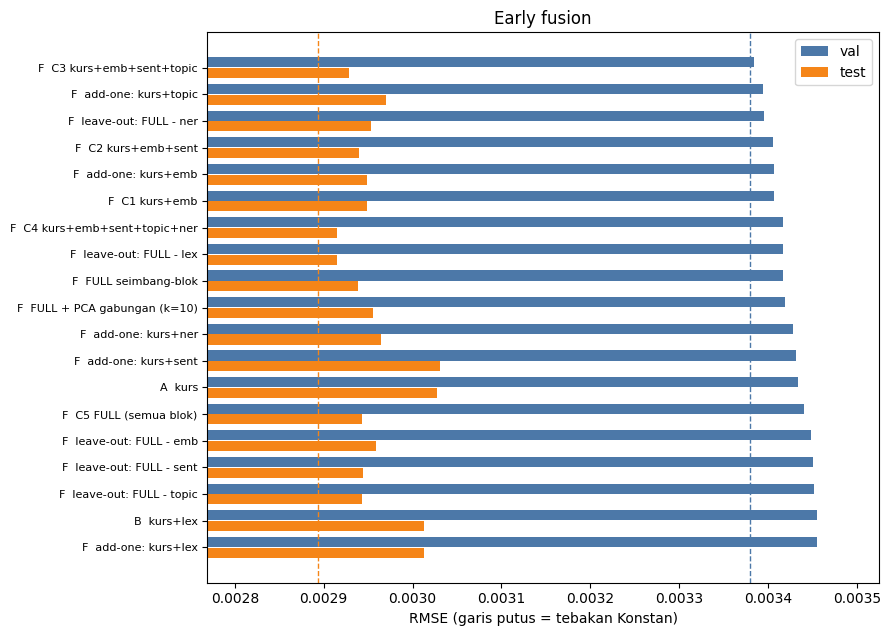

In [18]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlim(plot_df.min().min() * 0.95, plot_df.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend()
ax.set_title("Early fusion"); plt.tight_layout(); plt.show()

### 7.5 Kontribusi tiap blok
- **Add-one:** `dRMSE%` terhadap A untuk A + satu blok. - **Leave-out:** selisih FULL terhadap FULL tanpa blok itu; **positif** berarti membuang blok itu *memperbaiki* (blok itu merugikan), **negatif** berarti blok itu berguna.

In [19]:
rows7 = []
full_name = [s for s in mean_tbl.index if "FULL (semua blok)" in s][0]
for b in AV:
    a = f"F  add-one: kurs+{b}"; l = f"F  leave-out: FULL - {b}"
    r = {"blok": b}
    for sp in ("val", "test"):
        r[f"add-one dRMSE% {sp}"] = mean_tbl.loc[a, ("dRMSE%", sp)]
        r[f"leave-out vs FULL {sp}"] = 100 * (mean_tbl.loc[l, ("RMSE", sp)] / mean_tbl.loc[full_name, ("RMSE", sp)] - 1)
    rows7.append(r)
pd.DataFrame(rows7).set_index("blok").round(2)

,add-one dRMSE% val,leave-out vs FULL val,add-one dRMSE% test,leave-out vs FULL test
blok,,,,
lex,0.63,-0.68,-0.47,-0.97
emb,-0.78,0.23,-2.60,0.52
sent,-0.06,0.31,0.11,0.02
topic,-1.14,0.32,-1.92,0.01
ner,-0.16,-1.32,-2.07,0.33


### 7.6 Uji berpasangan (block bootstrap)
Untuk tiap set (prediksi rata-rata 3 model): selisih MSE per hari terhadap **A** dan terhadap **Konstan**, dengan selang kepercayaan 95% dari *moving block bootstrap* (blok 10 hari, menjaga autokorelasi). Nilai **negatif** = set lebih baik. Jika selang memuat 0, selisih tidak bisa dibedakan dari nol. Val dan test dihitung terpisah.

In [20]:
rng = np.random.default_rng(SEED)
def block_boot(d, block=10, nrep=2000):
    n = len(d); nb = int(np.ceil(n / block)); starts = np.arange(n - block + 1)
    means = np.empty(nrep)
    for r in range(nrep):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.choice(starts, nb)])[:n]
        means[r] = d[idx].mean()
    return d.mean(), *np.percentile(means, [2.5, 97.5])

const_pred = np.full(len(y), y[tr].mean())
out = []
for name, p in PRED.items():
    if name.startswith("A  "): continue
    r = {"set": name}
    for sp, mask in (("val", va), ("test", te)):
        yy = y[mask]; mse = lambda q: (yy - q[mask]) ** 2
        for ref_name, ref in (("A", PRED["A  kurs"]), ("Konstan", const_pred)):
            d = mse(p) - mse(ref); m, lo, hi = block_boot(d)
            base_mse = mse(ref).mean()
            r[f"{sp} vs {ref_name}"] = f"{100 * m / base_mse:+.1f}% [{100 * lo / base_mse:+.1f}, {100 * hi / base_mse:+.1f}]"
    out.append(r)
pd.DataFrame(out).set_index("set")

,val vs A,val vs Konstan,test vs A,test vs Konstan
set,,,,
B kurs+lex,"+1.3% [-3.6, +6.3]","+3.6% [-2.3, +9.4]","-1.3% [-6.3, +3.5]","+7.0% [+0.4, +15.5]"
F C1 kurs+emb,"-1.3% [-5.9, +3.5]","+1.0% [-3.5, +5.0]","-5.2% [-9.5, -1.2]","+2.8% [-3.2, +9.4]"
F C2 kurs+emb+sent,"-1.5% [-5.6, +2.2]","+0.8% [-3.8, +4.5]","-5.9% [-11.4, -1.5]","+2.1% [-3.3, +8.5]"
F C3 kurs+emb+sent+topic,"-3.5% [-8.0, +0.6]","-1.3% [-6.0, +3.1]","-7.0% [-13.4, -2.1]","+0.8% [-3.7, +5.6]"
F C4 kurs+emb+sent+topic+ner,"-1.9% [-6.0, +2.4]","+0.3% [-4.5, +4.8]","-8.5% [-15.7, -3.3]","-0.8% [-6.0, +4.3]"
F C5 FULL (semua blok),"-0.9% [-5.2, +3.3]","+1.3% [-3.9, +6.2]","-6.8% [-14.7, -0.4]","+1.0% [-4.0, +6.8]"
F add-one: kurs+lex,"+1.3% [-3.4, +6.3]","+3.6% [-2.4, +9.5]","-1.3% [-6.2, +4.0]","+7.0% [+0.6, +15.0]"
F add-one: kurs+emb,"-1.3% [-5.9, +3.5]","+1.0% [-3.3, +4.8]","-5.2% [-9.5, -1.2]","+2.8% [-3.2, +9.5]"
F add-one: kurs+sent,"-0.6% [-4.1, +2.7]","+1.7% [-4.5, +7.3]","-0.4% [-3.7, +2.2]","+8.0% [+0.5, +16.9]"


Selisih dinyatakan dalam % terhadap **MSE** pembanding (bukan RMSE), jadi angkanya sekitar dua kali dRMSE%. Hanya selang yang tidak memuat 0 pada **val dan test sekaligus** yang pantas disebut perbaikan nyata.

## 8. Catatan metodologi
- **Fitur dipilih di muka**, bukan dari val/test. Susunan blok dan urutan ablation ditetapkan sebelum melihat hasil fusi.
- **Early fusion rawan dimensi tinggi:** FULL punya puluhan fitur untuk 836 hari train. Strategi seimbang-blok dan PCA gabungan ada untuk menguji apakah dimensi menjadi masalah.
- **Pohon tidak terpengaruh skala**, jadi bobot seimbang-blok praktis hanya mengubah Ridge.
- **Banyak set diuji**; sebagian selisih kecil pasti kebetulan, terutama bila tidak konsisten antara val dan test.
- **Pembanding utama tetap baris Konstan.** Hasil Bagian A–B.v: tidak ada blok tunggal yang mengalahkannya; fusi menjawab apakah kombinasi bisa.

## 9. Kesimpulan 
Kesimpulan early fusion: menggabungkan blok membawa model sampai setara dengan Konstan, tapi belum melampauinya.

1. **Ablation bertahap (7.2):** apakah C1…C5 menurun/naik RMSE secara monoton? Apakah FULL lebih baik dari blok terbaik tunggal?
Menambah blok menurunkan error sedikit demi sedikit sampai C3, dan C4 hanya memperbaiki test.
C5 lebih buruk dari C4, jadi menambahkan lexicon memperburuk.
Hasil terbaik: C3 dengan RMSE val 0,00338 dan test 0,00293, vs Konstan 0,00338 dan 0,00289. C4 test 0,00291. Keduanya praktis sama dengan Konstan.

2. **Kontribusi blok (7.5):** blok mana yang berguna (leave-out negatif) dan mana yang merugikan?
Ada kesalahan pada keterangan yang saya tulis di notebook, jadi koreksi dulu. Kolom leave-out vs FULL = RMSE(FULL tanpa blok) / RMSE(FULL) − 1. Maka positif berarti blok itu berguna (membuangnya menaikkan error) dan negatif berarti blok itu merugikan. 

3. **Strategi (7.2):** apakah seimbang-blok atau PCA gabungan lebih baik dari concat mentah?
concat mentah (+0,19 / −2,79), seimbang-blok (−0,48 / −2,96), dan PCA gabungan (−0,41 / −2,40). Selisihnya kurang dari 1 poin, jadi tidak ada strategi yang jelas lebih baik.

4. **Uji berpasangan (7.6):** adakah set dengan selang yang tidak memuat 0 terhadap A, dan terhadap Konstan?
Terhadap A: di test, banyak set yang selangnya tidak memuat 0, misalnya C1 −5,2% [−9,5, −1,2], C3 −7,0% [−13,4, −2,1], dan C4 −8,5% [−15,7, −3,3] (dalam MSE). Di val, semua selang memuat 0 (C3 paling dekat, −3,5% [−8,0, +0,6]).
Terhadap Konstan: semua set yang bagus memuat 0 di val dan test. C3 val −1,3% [−6,0, +3,1] dan test +0,8% [−3,7, +5,6], C4 val +0,3% dan test −0,8%. Hanya lex (test +7,0% [+0,4, +15,5]) dan sent sendirian (test +8,0% [+0,5, +16,9]) yang terbukti lebih buruk dari Konstan.

5. Rekomendasi untuk **Model C final** dan alasan memakai (atau tidak) early fusion dibanding late fusion.
C3 (kurs + emb + sent + topic) paling masuk akal, atau tanpa sent karena kontribusinya nol, dan tanpa lexicon. Kalau ingin NER ikut, C4 sebagai varian.